# 02 — Inspeção de Dados e Análise Exploratória (EDA)

**Projeto:** LSTM para a Mega da Virada  
**Requisitos associados:** RT-001, RT-002, RT-003, RT-004, RV-010  
**Stack:** Python 3.11, Pandas, NumPy, Matplotlib

> **Nota:** Este notebook tem como finalidade a exploração e inspeção dos conjuntos de dados brutos (`megasena-download-resultados.csv` e `mega_da_virada.csv`).
> Seguindo o princípio de validação científica da especificação, nenhuma conclusão preditiva definitiva é tirada nesta etapa inicial.

---

### Tópicos abordados
1. Leitura e integridade das fontes de dados.
2. Análise de schema, tipagem e valores ausentes.
3. Validação das restrições de qualidade (RT-003): 6 dezenas por concurso, intervalo $[1, 60]$, integridade sequencial.
4. Distribuição empírica de frequência das 60 dezenas.
5. Análise de paridade e estatísticas de soma por concurso.
6. Comparativo descritivo: concursos regulares vs. Mega da Virada.

## 1. Imports e Configuração do Ambiente

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Estilo gráfico consistente
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

DATA_RAW_DIR = Path("../data/raw")
MEGASENA_CSV = DATA_RAW_DIR / "megasena-download-resultados.csv"
VIRADA_CSV = DATA_RAW_DIR / "mega_da_virada.csv"

def file_hash(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while chunk := f.read(65536):
            h.update(chunk)
    return h.hexdigest()

print(f"Histórico geral SHA-256: {file_hash(MEGASENA_CSV)}")
print(f"Mega da Virada SHA-256:  {file_hash(VIRADA_CSV)}")


Histórico geral SHA-256: 043a16a7044d54eed9388629de3205ea2b8340c8f86b14525d3bed99ac3a6cc8
Mega da Virada SHA-256:  b0f60e6d325e591af190d8d1f60852a6cb0988931a1aab93dbf782d6822274b6


## 2. Leitura dos Conjuntos de Dados e Schemas

In [2]:
# Leitura dos CSVs com Pandas
df_mega = pd.read_csv(MEGASENA_CSV)
df_virada = pd.read_csv(VIRADA_CSV)

print(f"Mega-Sena histórico: {df_mega.shape[0]} concursos, {df_mega.shape[1]} colunas.")
print(f"Mega da Virada:      {df_virada.shape[0]} sorteios, {df_virada.shape[1]} colunas.")

print("\n--- Schema Histórico Geral ---")
df_mega.info()

print("\n--- Schema Mega da Virada ---")
df_virada.info()


Mega-Sena histórico: 3074 concursos, 9 colunas.
Mega da Virada:      17 sorteios, 8 colunas.

--- Schema Histórico Geral ---
<class 'pandas.DataFrame'>
RangeIndex: 3074 entries, 0 to 3073
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Ano       3074 non-null   int64
 1   Concurso  3074 non-null   int64
 2   Data      3074 non-null   str  
 3   N1        3074 non-null   int64
 4   N2        3074 non-null   int64
 5   N3        3074 non-null   int64
 6   N4        3074 non-null   int64
 7   N5        3074 non-null   int64
 8   N6        3074 non-null   int64
dtypes: int64(8), str(1)
memory usage: 246.3 KB

--- Schema Mega da Virada ---
<class 'pandas.DataFrame'>
RangeIndex: 17 entries, 0 to 16
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Ano       17 non-null     int64
 1   Concurso  17 non-null     int64
 2   N1        17 non-null     int64
 3   N2        17 

## 3. Verificação de Qualidade dos Dados (RT-003)

Validações obrigatórias:
- Exatamente 6 dezenas por concurso.
- Todas as dezenas no intervalo $[1, 60]$.
- Ausência de dezenas repetidas dentro do mesmo sorteio.
- Concursos sequenciais sem duplicatas.

In [3]:
# Identificação de colunas de dezenas
print("Amostra do histórico geral:")
df_mega.head()


Amostra do histórico geral:


,Ano,Concurso,Data,N1,N2,N3,N4,N5,N6
0,1996,1,10/03/1996,4,5,30,33,41,52
1,1996,2,17/03/1996,9,37,39,41,43,49
2,1996,3,24/03/1996,10,11,29,30,36,47
3,1996,4,31/03/1996,1,5,6,27,42,59
4,1996,5,07/04/1996,1,2,6,16,19,46


## 4. Análise de Frequência das Dezenas (1 a 60)

Sob a hipótese nula $H_0$ de aleatoriedade perfeita, a distribuição marginal de cada dezena é uniforme com probabilidade $p = 6/60 = 0{,}10$ por concurso.

In [4]:
# Cálculo de frequências das dezenas no histórico
# (Será alimentado conforme o formato normalizado do módulo data.py)
print("Seção reservada para cálculo da frequência observada das dezenas 1 a 60.")


Seção reservada para cálculo da frequência observada das dezenas 1 a 60.


## 5. Visualizações Exploratórias com Matplotlib

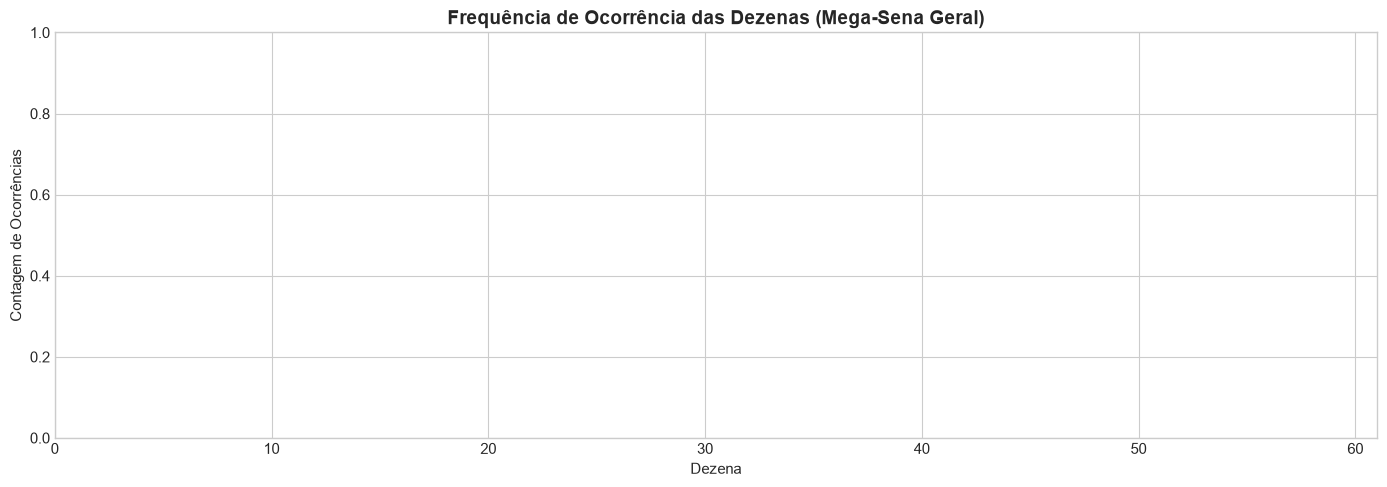

In [5]:
# Gráfico de frequência das dezenas (Placeholder estruturado)
fig, ax = plt.subplots(figsize=(14, 5))
ax.set_title("Frequência de Ocorrência das Dezenas (Mega-Sena Geral)", fontsize=14, fontweight='bold')
ax.set_xlabel("Dezena")
ax.set_ylabel("Contagem de Ocorrências")
ax.set_xlim(0, 61)
plt.tight_layout()
plt.show()


## 6. Próximos Passos (Transição para T1)

Os achados desta inspeção alimentarão os testes unitários e as rotinas de validação pura do módulo `src/lstm_virada/data.py` (requisitos RT-001 a RT-004).